# Data script validation

Checks the files written by `python -m project.data` and `python -m project.features`:

| File | Made by |
|---|---|
| `data/raw/futures_close.parquet` | `data.py` |
| `data/processed/xtrend_features.parquet` | `features.py --steps processed` |
| `data/processed/cpd_scores.parquet`, `cpd_regimes.parquet` | `features.py --steps cpd` |



In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "src"))
from project import features as F
from project.data import ROOT

cfg = F.load_config()
raw = pd.read_parquet(ROOT / cfg["raw_path"])
feat = pd.read_parquet(ROOT / cfg["processed_path"]).sort_values(["ticker", "date"])
scores = pd.read_parquet(ROOT / cfg["cpd_scores_path"])
regimes = pd.read_parquet(ROOT / cfg["regimes_path"])
FEATURES = F.feature_columns(cfg)
files = {"raw": raw, "processed": feat, "cpd_scores": scores, "cpd_regimes": regimes}

## 1. Size, nulls and duplicates

In [2]:
keys = {"raw": ["ticker", "date"], "processed": ["ticker", "date"],
        "cpd_scores": ["ticker", "date"],
        "cpd_regimes": ["ticker", "max_length", "start_date"]}
pd.DataFrame({name: {"rows": len(d),
                     "tickers": d["ticker"].nunique(),
                     "null cells": int(d.isna().sum().sum()),
                     "duplicate keys": int(d.duplicated(keys[name]).sum())}
              for name, d in files.items()}).T

,rows,tickers,null cells,duplicate keys
raw,383507,49,52,0
processed,362675,49,0,0
cpd_scores,368215,49,23,0
cpd_regimes,38416,49,0,0


Nulls by column (only columns that have any). Raw `ret` is null on the first day of a contract's price history, when there is no previous price; it only matters on a ticker's very first row. `cp_days_back` is null when a window is flat, because a flat window has no change point.

In [3]:
nulls = pd.concat({n: d.isna().sum() for n, d in files.items()}).rename("nulls")
nulls[nulls > 0].to_frame() if (nulls > 0).any() else "no nulls in any file"

,,nulls
raw,ret,52
cpd_scores,cp_days_back,23


## 2. Proportion of data available

Each row is one trading day with a price. **Available** = rows / business days, measured two ways:

- *own span*: from the ticker's first to last row, so it shows gaps inside its history.
- *full sample*: from `sample_start` to `end_date`, so it also shows futures that start late or end early.

In [4]:
start, end = pd.Timestamp(cfg["features"]["sample_start"]), pd.Timestamp(cfg["end_date"])
n_full = len(pd.bdate_range(start, end))

def coverage(g):
    d = g["date"]
    return pd.Series({"sector": g["sector"].iat[0], "first": d.min().date(), "last": d.max().date(),
                      "rows": len(g),
                      "own span": len(g) / len(pd.bdate_range(d.min(), d.max())),
                      "full sample": len(g) / n_full})

cov = feat.groupby("ticker").apply(coverage, include_groups=False).sort_values("full sample")
print(f"overall: {len(feat) / (n_full * len(cov)):.1%} of all ticker x business-day slots have data")
cov.style.format({"own span": "{:.1%}", "full sample": "{:.1%}"})

overall: 83.4% of all ticker x business-day slots have data


,sector,first,last,rows,own span,full sample
ticker,,,,,,
RTY,EQ,2018-10-01,2023-12-28,1323,96.6%,14.9%
GSCI,CM,2008-04-22,2023-12-28,3958,96.7%,44.6%
ZL,CM,2007-06-22,2023-12-28,4166,96.7%,47.0%
ZW,CM,2005-10-14,2023-12-28,4590,96.6%,51.7%
MD,EQ,2005-03-17,2023-12-28,4737,96.7%,53.4%
HE,CM,2002-03-18,2023-12-28,5489,96.6%,61.9%
ZR,CM,2001-03-27,2023-12-28,5735,96.6%,64.7%
NQ,EQ,2000-09-11,2023-12-28,5875,96.6%,66.2%
BOBL,FI,1999-12-27,2023-12-28,6113,97.6%,68.9%


Share of business days with data, per ticker and year (white = no data that year).

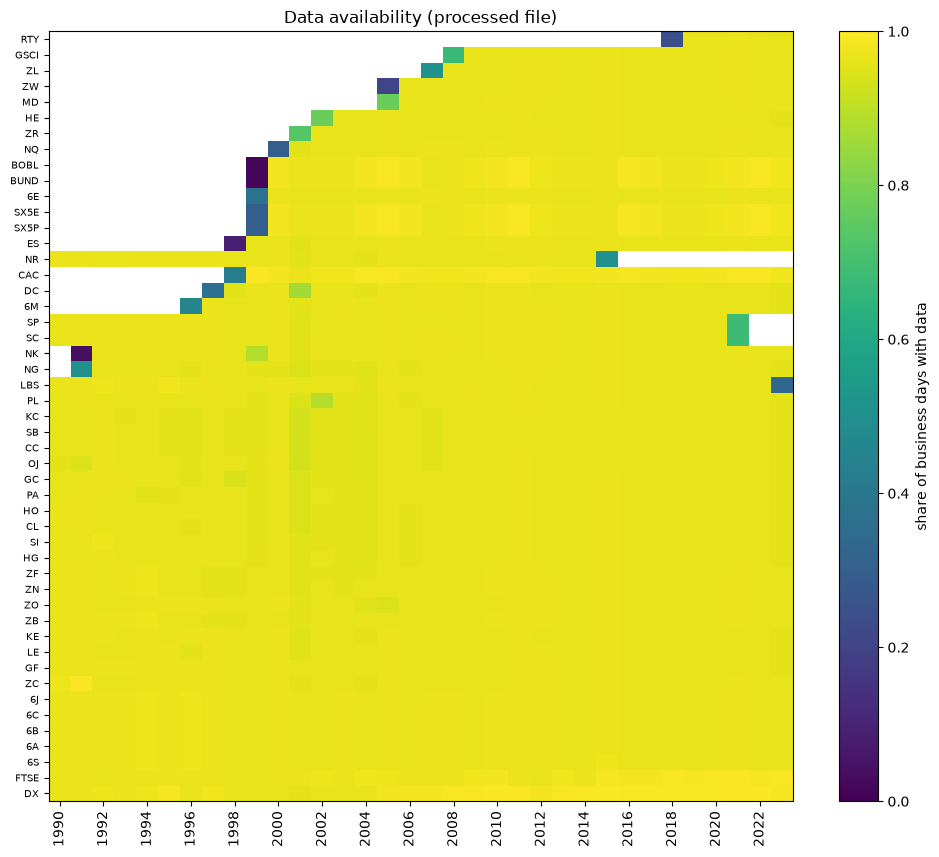

In [5]:
yearly = (feat.assign(year=feat["date"].dt.year).groupby(["ticker", "year"]).size().unstack()
          .div(pd.Series({y: len(pd.bdate_range(max(start, pd.Timestamp(f"{y}-01-01")),
                                                min(end, pd.Timestamp(f"{y}-12-31"))))
                          for y in range(start.year, end.year + 1)}))
          .reindex(cov.index))
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(yearly, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_yticks(range(len(yearly)), yearly.index, fontsize=7)
ax.set_xticks(range(0, yearly.shape[1], 2), yearly.columns[::2], rotation=90)
fig.colorbar(im, label="share of business days with data")
ax.set_title("Data availability (processed file)")
plt.show()

Gaps: business days between consecutive rows. 1 is normal, 2 is usually a holiday. Long gaps are listed. Gaps are not filled: the model treats the next row as the next time step. The raw file also has gaps in DC (1997) and GSCI (2007), but they fall in the first 252 days of those tickers, which the processed file drops because the long-horizon features need that much history.

In [6]:
day = lambda s: s.values.astype("datetime64[D]")
prev = feat.groupby("ticker")["date"].shift()
has = prev.notna()
gaps = feat.loc[has, ["ticker", "date"]].assign(prev=prev[has])
gaps["gap"] = np.busday_count(day(gaps["prev"]), day(gaps["date"]))
print(gaps["gap"].value_counts().sort_index().rename("rows").to_string())
gaps[gaps["gap"] >= 5].sort_values("gap", ascending=False)

gap
1     350908
2      11023
3        627
4         58
5          6
7          1
20         1
22         1
28         1


,ticker,date,prev,gap
92684,DC,2001-05-01,2001-03-22,28
214666,NK,2000-01-03,1999-12-02,22
253178,PL,2002-05-22,2002-04-24,20
124229,GC,1998-09-22,1998-09-11,7
77643,CC,2001-09-17,2001-09-10,5
168619,KC,2001-09-17,2001-09-10,5
235954,OJ,2001-09-17,2001-09-10,5
253028,PL,2001-09-17,2001-09-10,5
262867,SB,2001-09-17,2001-09-10,5
287964,SP,2001-09-17,2001-09-10,5


## 3. Sanity checks

In [7]:
r = raw.sort_values(["ticker", "date"])
adj_ret = r.groupby("ticker")["adj_close"].pct_change()
last = r.groupby("ticker").tail(1)
exp_target = feat["next_ret"] * cfg["features"]["vol_target"] / (feat["sigma"] * np.sqrt(252))
scored = feat.merge(scores, on=["ticker", "date"], how="left")

checks = {
    "tickers match config": set(raw["ticker"]) == set(cfg["universe"]),
    "close and adj_close > 0": bool((raw[["close", "adj_close"]] > 0).all().all()),
    "latest adj_close = close": bool(np.allclose(last["adj_close"], last["close"])),
    "adj returns = contract returns": bool(np.allclose(adj_ret.dropna(),
                                                       r["ret"].fillna(0)[adj_ret.notna()])),
    "processed dates within sample": bool(feat["date"].between(start, end).all()),
    "target = next_ret * 0.15 / annual vol": bool(np.allclose(feat["target"], exp_target)),
    "every processed row has a CPD score": bool(scored["severity"].notna().all()),
    "severity in [0, 1]": bool(scores["severity"].between(0, 1).all()),
    "regime lengths >= min_length": bool((regimes["length"] >= cfg["cpd"]["min_length"]).all()),
}
pd.Series(checks, name="pass").to_frame()

,pass
tickers match config,True
close and adj_close > 0,True
latest adj_close = close,True
adj returns = contract returns,True
processed dates within sample,True
target = next_ret * 0.15 / annual vol,True
every processed row has a CPD score,True
"severity in [0, 1]",True
regime lengths >= min_length,True


## 4. Feature and target summary

Inputs should be roughly unit scale. `target` is scaled to 15% annual volatility, so its annualised std should be close to 0.15.

In [8]:
summary = feat[FEATURES + ["target", "next_ret", "sigma"]].describe(
    percentiles=[0.01, 0.99]).T[["mean", "std", "min", "1%", "99%", "max"]]
print(f"target annualised std: {feat['target'].std() * np.sqrt(252):.3f}")
summary.round(3)

target annualised std: 0.156


,mean,std,min,1%,99%,max
ret_1,0.016,0.978,-5.352,-2.431,2.369,5.554
ret_21,0.087,0.998,-4.191,-2.140,2.481,8.492
ret_63,0.158,1.025,-3.904,-1.965,2.734,10.196
ret_126,0.224,1.087,-5.024,-1.891,3.057,16.688
ret_252,0.313,1.229,-6.282,-1.888,3.712,30.154
macd_8_24,0.133,1.278,-8.114,-2.449,2.870,8.856
macd_16_48,0.208,1.777,-10.504,-4.129,4.841,11.350
macd_32_96,0.272,2.110,-10.674,-5.027,5.490,11.543
target,0.000,0.010,-0.183,-0.025,0.024,0.537
next_ret,0.000,0.015,-0.434,-0.043,0.043,0.386


## 5. CPD regimes

The paper calibrates each threshold so the mean regime length (capped at `max_length`, as the sampler uses it) is about half of `max_length`.

In [9]:
(regimes.assign(used=regimes["length"].clip(upper=regimes["max_length"]))
        .groupby(["max_length", "threshold"])
        .agg(regimes=("length", "size"), tickers=("ticker", "nunique"),
             mean_used=("used", "mean"), median=("length", "median"), longest=("length", "max"))
        .assign(paper_target=lambda d: d.index.get_level_values("max_length") / 2)
        .round(1))

,,regimes,tickers,mean_used,median,longest,paper_target
max_length,threshold,,,,,,
21,0.90,20176,49,15.2,17.0,40,10.5
63,0.95,18240,49,18.1,18.0,78,31.5


## Potential Issues
1. DC has a multi week gap (we could potentially drop) (same with NY and PL)
2. RTY is very short (14% of our window, could potentially drop)
3. GSCI (Goldman) has some data jump issues with potential placeholder values until trading officially starts on 2015-06-10, causing an artificial ~30% positive jump. 